[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch52_LabCh52_Flow_Matching_2D.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 52: Flow Matching and Fast Generation** (Part XI: Imagining in Depth).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=52](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=52)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch52 - Flow matching in two dimensions
## Draw straight lines from noise to data, learn the velocity, then follow the arrows in as few steps as you dare

This lab goes with **Chapter 52** of *The Why Book of Deep Learning, Part 2*.

Chapter 50 turned noise into two moons with a thousand small, jittery steps. This lab reaches the same
moons by a different route. It draws a **straight line** from each noise point to a data point, teaches
the same small network the **velocity** along those lines, and then generates by following the learnt
arrows. Then it asks the question the whole chapter is about: how few steps can you take?

| Piece | Chapter 50's lab | This lab |
|---|---|---|
| data | two moons, 8,000 points | the same points, from the same function |
| path from data to noise | a schedule of 1,000 noising steps | a straight line, position = (1 - t) × noise + t × data |
| network | MLP, 54,274 parameters | the same MLP, built by the same function |
| target | the noise that was added | the velocity: data - noise |
| sampler | ancestral, 1,000 steps, fresh noise each step | Euler, 1 to 100 steps, no fresh noise |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build flow-matching training pairs and say which end of time is noise | Step 3 |
| Write the five-line training step and say what an untrained network should score | Steps 5 and 6 |
| Generate by Euler integration and measure quality against the number of steps | Steps 8 and 9 |
| Explain with a number why one step fails on a plain flow-matching model | Step 10 |
| Measure how straight the paths are, and draw the velocity field as arrows | Steps 10 and 11 |
| Show that the sampler is a fixed map from noise to data | Step 12 |
| Recognise a reversed time convention from its samples | Step 13 |
| Rectify a flow: make pairs with the model, retrain, and sample in one step | Steps 14 to 16 |
| State what rectification cost, round by round | Step 17 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **The time convention of this lab and of Chapter 52: t = 0 is noise, t = 1 is data.** Sampling runs
> *forwards* in time, from 0 to 1. This is the opposite of Chapters 50 and 51, where step 0 was clean data
> and step 1,000 was noise. Papers and libraries use both. Step 13 shows what happens when two pieces of
> code disagree.

> **Runtime:** about three minutes on a laptop CPU. Steps 6, 15 and 17 are the three training runs (about
> half a minute each, longer on a busy machine). No GPU and no downloads are needed.

> **Honest scale:** this is a miniature: 8,000 points with two numbers each and a network of 54,274
> parameters. Image and video generators trained by flow matching have hundreds of millions to billions of
> parameters and work on latents with thousands of numbers. The **method** here is the real one. The
> **numbers** (how many steps are enough, what rectification costs) are small-model numbers, for comparing
> runs inside this notebook with each other and with Chapter 50's lab.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 52
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=4, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The data: Chapter 50's two moons, unchanged

`make_points`, `nearest_dist` and `score` are copied from Chapter 50's notebook without a change, so that
every number here can be put beside a number there. Two yardsticks, smaller is better for both:

- **off**: how far a generated point is from the nearest training point (is it on a moon?). The headline
  figure is the share of generated points further than 0.1 from any moon.
- **miss**: how far a real point is from the nearest generated point (is every part of the moons covered?).

Chapter 50's ancestral sampler, with 1,000 steps, left **1.1%** of its points off the moons. Its one-jump
shortcut from step 500 left 66.8%. Keep both in mind.

> **Predict:** fresh real points are the best any generator can do. What will "off" be for them: exactly
> zero, or a small number? Why?

In [2]:
def make_points(n=8000, seed=0):
    """Two interleaved moons. Returns (points of shape (n, 2) float32, moon label of shape (n,))."""
    rng = np.random.default_rng(seed)
    half = n // 2
    a = rng.uniform(0, np.pi, half)
    b = rng.uniform(0, np.pi, n - half)
    upper = np.stack([np.cos(a), np.sin(a)], axis=1)                 # moon 0: an arch
    lower = np.stack([1 - np.cos(b), 0.5 - np.sin(b)], axis=1)       # moon 1: a bowl, shifted right
    x = np.concatenate([upper, lower]) + rng.normal(0, 0.06, (n, 2)) # a little thickness
    y = np.concatenate([np.zeros(half, dtype="int32"), np.ones(n - half, dtype="int32")])
    x = (x - np.array([0.5, 0.25])) / 0.9                            # centre, and scale to roughly unit size
    order = rng.permutation(n)
    return x[order].astype("float32"), y[order]

def nearest_dist(a, b):
    """For every point in a, the distance to its nearest point in b."""
    d2 = ((a[:, None, :] - b[None, :, :]) ** 2).sum(-1)
    return np.sqrt(d2.min(axis=1))

def lims(ax, r=2.6):
    ax.set_xlim(-r, r); ax.set_ylim(-r, r); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

X, Y = make_points(8000, seed=0)             # the training set
X_REAL, _ = make_points(2000, seed=1)        # fresh points from the same moons, never trained on
X_REAL2, _ = make_points(2000, seed=2)       # and a second fresh set, for a yardstick
print("X:", X.shape, X.dtype, "| labels:", np.bincount(Y))
print("mean:", X.mean(0).round(3), "| std:", X.std(0).round(3))

def score(samples, name):
    off = nearest_dist(samples, X).mean()
    miss = nearest_dist(X_REAL, samples).mean()
    far = (nearest_dist(samples, X) > 0.1).mean()
    print(f"{name:34s} off {off:.3f} | miss {miss:.3f} | further than 0.1 from any moon: {100 * far:5.1f}% | std {samples.std(0).round(2)}")
    return off, miss, far

REAL_SCORE = score(X_REAL2, "2,000 fresh real points")

X: (8000, 2) float32 | labels: [4000 4000]
mean: [0.005 0.004] | std: [0.965 0.552]


2,000 fresh real points            off 0.009 | miss 0.017 | further than 0.1 from any moon:   0.0% | std [0.97 0.55]


### Why we see this

Real points score an "off" of about 0.009, not zero: a new point never lands exactly on an old one. None
of them is further than 0.1 from a moon. These are the numbers a perfect generator would print.

---
## Step 3 - The path: a straight line from a noise point to a data point

Generation is a **transport** problem. A round cloud of noise points has to be moved so that it lies on
the moons. Flow matching starts by choosing the simplest possible route for each point.

1. Pick a data point, `x1`.
2. Pick a noise point, `x0`, from a random number generator. Any noise point: the two are paired by chance.
3. Join them with a straight line. At time t the traveller is at **(1 - t) × x0 + t × x1**.

At t = 0 that is the noise point; at t = 1 it is the data point. The traveller moves at a constant
**velocity**, `x1 - x0`: the whole displacement, covered in one unit of time.

> **Predict:** take all 8,000 pairs and look at where the travellers are at t = 0.5. Is that cloud wider
> or narrower than the noise cloud? (Each coordinate is half a noise number plus half a data number, and
> the two are independent. Variances add, weighted by the squares of the halves.)

   t   std of the cloud (x, y)   predicted from the two variances
 0.00   [0.999 0.988]           [1. 1.]
 0.25   [0.784 0.753]           [0.788 0.763]
 0.50   [0.69  0.564]           [0.695 0.571]
 0.75   [0.762 0.481]           [0.766 0.483]
 1.00   [0.965 0.552]           [0.965 0.552]
mean length of a path (noise point to its data point): 1.601


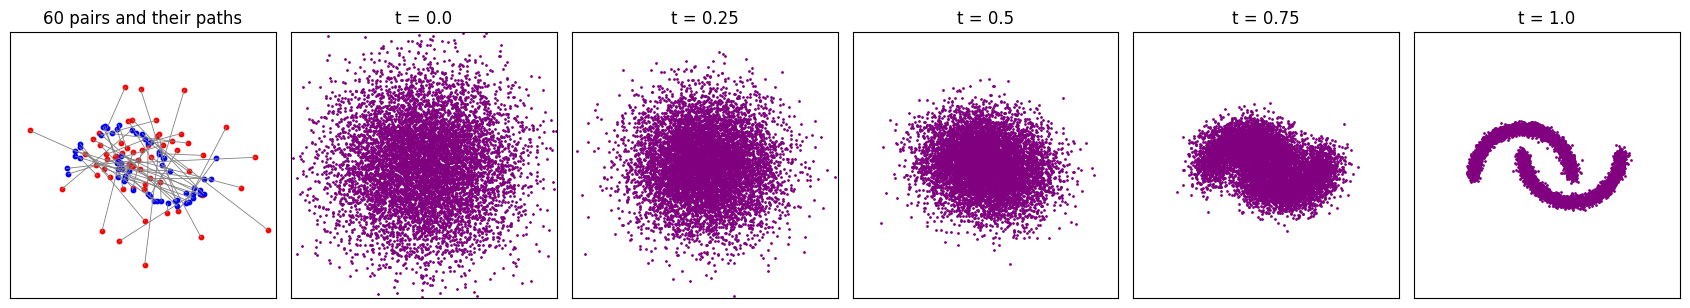

In [3]:
rng = np.random.default_rng(SEED)
x1 = X                                                  # the data end of every path: t = 1
x0 = rng.standard_normal(x1.shape).astype("float32")    # the noise end of every path: t = 0

def on_the_path(x0, x1, t):
    """Where the travellers are at time t (t = 0: noise, t = 1: data)."""
    return (1 - t) * x0 + t * x1

print("   t   std of the cloud (x, y)   predicted from the two variances")
for t in (0.0, 0.25, 0.5, 0.75, 1.0):
    cloud = on_the_path(x0, x1, t)
    pred = np.sqrt((1 - t) ** 2 * 1.0 + t ** 2 * X.var(0))
    print(f"{t:5.2f}   {cloud.std(0).round(3)}           {pred.round(3)}")
print("mean length of a path (noise point to its data point):", np.linalg.norm(x1 - x0, axis=1).mean().round(3))

fig, ax = plt.subplots(1, 6, figsize=(17, 3.1))
for i in range(60):
    ax[0].plot([x0[i, 0], x1[i, 0]], [x0[i, 1], x1[i, 1]], c="grey", lw=0.6)
ax[0].scatter(x0[:60, 0], x0[:60, 1], s=10, c="red"); ax[0].scatter(x1[:60, 0], x1[:60, 1], s=10, c="blue")
lims(ax[0], 3.0); ax[0].set_title("60 pairs and their paths")
for a, t in zip(ax[1:], (0.0, 0.25, 0.5, 0.75, 1.0)):
    c = on_the_path(x0, x1, t); a.scatter(c[:, 0], c[:, 1], s=1, c="purple"); lims(a, 3.0); a.set_title(f"t = {t}")
plt.tight_layout(); plt.show()

### Why we see this

At t = 0.5 the cloud is **narrower** than the noise: half of a noise number has a quarter of its variance,
and half of a data number adds a little back. Unlike Chapter 50's schedule, the straight path does not keep
the spread constant on the way. Nothing requires it to. Both ends are right, and that is all that matters.

Look at the first panel. The 60 paths **cross** everywhere: pairs were made by chance, so a noise point
on the far left may be sent to the far right. Hold on to that picture. If two travellers pass through the
same place at the same time heading in different directions, a network that sees only the place and the
time cannot tell which one it is looking at. Step 6 and Step 10 show what it does about that.

Like Chapter 50's forward process, all of this is arithmetic. Nothing has been learnt yet.

---
## Step 4 - The network: the same one, with a new job

`TimeEmbedding` and `build_denoiser` are copied from Chapter 50's notebook without a change. In: a point
(2 numbers) and the time. Out: 2 numbers with no activation. In Chapter 50 those two numbers were a guess
of the noise. Here they are a guess of the **velocity**: which way, and how fast, a point at this place
and time should move. (The output layer is still called `noise` inside the function, because the function
is copied verbatim. The name does not change what it learns; the target does.)

The time embedding was written for integer steps from 0 to 1,000, so this lab gives the network the time
in **thousandths**: `k = 1000 × t`, a whole number from 0 to 999 in training. One convention, used by both
the training step and the sampler.

> **Predict:** same function, same arguments as Chapter 50. How many parameters?

In [4]:
class TimeEmbedding(layers.Layer):
    """Integer step t, shape (batch,)  ->  sinusoidal vector, shape (batch, dim). No weights."""
    def __init__(self, dim=32, max_period=10000.0, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim
        self.max_period = max_period

    def call(self, t):
        ops = keras.ops
        t = ops.cast(ops.reshape(t, (-1, 1)), "float32")
        half = self.dim // 2
        freqs = ops.exp(-np.log(self.max_period) * ops.arange(half, dtype="float32") / half)
        angles = t * ops.reshape(freqs, (1, -1))
        return ops.concatenate([ops.sin(angles), ops.cos(angles)], axis=-1)

    def get_config(self):
        return {**super().get_config(), "dim": self.dim, "max_period": self.max_period}

def build_denoiser(dim=2, width=128, depth=4, emb_dim=32, use_time=True, name="denoiser"):
    """An MLP that predicts the noise in x_t. Inputs: x_t of shape (dim,), and the integer step t.
    use_time=False multiplies the time embedding by zero (for the experiment in Step 15)."""
    x_in = layers.Input(shape=(dim,), name="x_t")
    t_in = layers.Input(shape=(), dtype="int32", name="t")
    e = TimeEmbedding(emb_dim, name="time_embedding")(t_in)
    if not use_time:
        e = layers.Rescaling(0.0, name="time_switched_off")(e)
    h = layers.Concatenate(name="join")([x_in, e])
    for i in range(depth):
        h = layers.Dense(width, activation="swish", name=f"dense{i + 1}")(h)
    out = layers.Dense(dim, name="noise")(h)                       # no activation: noise has no range
    return keras.Model([x_in, t_in], out, name=name)

TICKS = 1000                                   # the network's clock: k = TICKS * t, t = 0 noise, t = 1 data
MLP_HAND = (2 + 32 + 1) * 128 + 3 * (128 + 1) * 128 + (128 + 1) * 2
keras.utils.set_random_seed(SEED)
flow1 = build_denoiser(name="flow1")
assert flow1.count_params() == MLP_HAND == 54_274
print(f"hand count: (2 + 32 + 1) x 128 + 3 x (128 + 1) x 128 + (128 + 1) x 2 = {MLP_HAND:,}")
print("model     :", f"{flow1.count_params():,}", "| input shapes:", [tuple(i.shape) for i in flow1.inputs], "| output shape:", flow1.output_shape)

hand count: (2 + 32 + 1) x 128 + 3 x (128 + 1) x 128 + (128 + 1) x 2 = 54,274
model     : 54,274 | input shapes: [(None, 2), (None,)] | output shape: (None, 2)


### Why we see this

**54,274**, to the last weight, the same as Chapter 50's noise predictor. Flow matching did not need a
new kind of network. It is a different **target** and a different **path** for the same one.

---
## Step 5 - One training step, by hand

Five lines: pick data, pick noise, pick a time for each pair, put the traveller on its line, and ask the
network for the velocity. The loss is mean squared error against the true velocity, `x1 - x0`.

> **Predict:** a network that always answers "velocity (0, 0)" scores the mean square of `x1 - x0`. The
> noise has variance 1 in each coordinate and the data has variances of about 0.94 and 0.30. What is the
> score, averaged over the two coordinates?

In [5]:
rng = np.random.default_rng(SEED)
x1 = X[:512]                                                    # 1. some data (the t = 1 end)
x0 = rng.standard_normal(x1.shape).astype("float32")            # 2. noise (the t = 0 end)
k = rng.integers(0, TICKS, size=len(x1))                        # 3. a time for every pair, in thousandths
t = (k / TICKS).astype("float32")[:, None]
x_t = (1 - t) * x0 + t * x1                                     # 4. a point on the straight path
loss = np.mean((flow1.predict([x_t, k], verbose=0) - (x1 - x0)) ** 2)   # 5. how wrong is the velocity?

print("times drawn (first 8):", (k[:8] / TICKS))
print(f"loss of an untrained network     : {loss:.3f}")
print(f"loss of 'always answer zero'     : {np.mean((x1 - x0) ** 2):.3f}")
print(f"predicted: 1 + (0.94 + 0.30) / 2 = {1 + (X.var(0).sum()) / 2:.3f}")

times drawn (first 8): [0.323 0.064 0.434 0.936 0.518 0.222 0.298 0.368]
loss of an untrained network     : 1.604
loss of 'always answer zero'     : 1.613
predicted: 1 + (0.94 + 0.30) / 2 = 1.618


### Why we see this

Knowing nothing scores about **1.6**: the noise's variance of 1 plus the data's average variance of 0.62.
That is the number to read this loss against, as 1.0 was in Chapter 50.

---
## Step 6 - Train

`train_flow` repeats those five lines. Each round it draws a fresh noise partner and a fresh time for
every data row (80,000 rows: the 8,000 points ten times over), then lets Keras do one pass of regression:
input `[x_t, k]`, target `x1 - x0`, loss MSE. The settings (40 rounds, batch 512, Adam with a cosine
decay from 0.002) are those of Chapter 50's lab, so the two networks have had the same amount of training.

If `noise` is given, the function uses those noise points, row for row, instead of fresh ones. Step 15
needs that.

> **Predict:** the loss starts near 1.6. Paths cross, so the same place and time appear in training with
> many different velocities. Can the loss go anywhere near zero?

round   1 / 40   loss 1.2426


round   6 / 40   loss 1.0921


round  11 / 40   loss 1.0670


round  16 / 40   loss 1.0630


round  21 / 40   loss 1.0561


round  26 / 40   loss 1.0543


round  31 / 40   loss 1.0552


round  36 / 40   loss 1.0528


round  40 / 40   loss 1.0592
trained in 23 s: 6,280 steps of batch 512


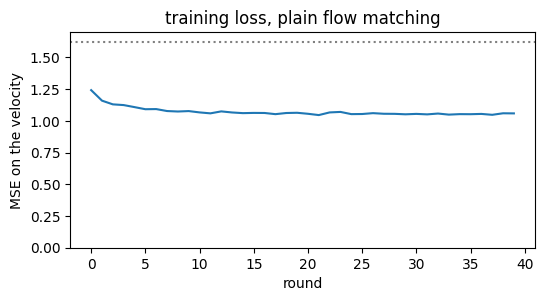

In [6]:
def train_flow(model, data, noise=None, rounds=40, batch=512, lr=2e-3, seed=0, verbose=True):
    """Flow-matching training. data: the t = 1 ends. noise: fixed t = 0 partners, or None for fresh random ones.
    Returns the mean loss of each round."""
    rng = np.random.default_rng(seed)
    steps = rounds * int(np.ceil(len(data) / batch))
    model.compile(optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(lr, steps)), loss="mse")
    history = []
    for r in range(rounds):
        x0 = rng.standard_normal(data.shape).astype("float32") if noise is None else noise   # the noise end
        k = rng.integers(0, TICKS, size=len(data))                     # a random time for every pair
        t = (k / TICKS).astype("float32")[:, None]
        x_t = (1 - t) * x0 + t * data                                  # a point on the straight path
        h = model.fit([x_t, k], data - x0, batch_size=batch, epochs=1, verbose=0)   # target: the velocity
        history.append(h.history["loss"][0])
        if verbose and (r % max(1, rounds // 8) == 0 or r == rounds - 1):
            print(f"round {r + 1:3d} / {rounds}   loss {history[-1]:.4f}")
    return history

DATA = np.tile(X, (10, 1))                                  # 80,000 rows
t0 = time.time()
hist1 = train_flow(flow1, DATA, rounds=40, seed=SEED)
TRAIN1_S = time.time() - t0
print(f"trained in {TRAIN1_S:.0f} s: {40 * int(np.ceil(len(DATA) / 512)):,} steps of batch 512")

plt.figure(figsize=(6, 2.8)); plt.plot(hist1); plt.axhline(1.62, color="grey", ls=":"); plt.ylim(0, 1.7)
plt.xlabel("round"); plt.ylabel("MSE on the velocity"); plt.title("training loss, plain flow matching"); plt.show()

### Why we see this

The loss falls from 1.6 to a little above **1.0** within a few rounds and stays there. It is not going to
zero, and that is not a failure. At a given place and time the training set holds travellers going many
ways, and the answer that minimises squared error against many targets is their **average** (Chapter 6).
What is left over, a little above 1.05, is the spread of the true velocities round that average. It is a property
of crossing paths, and no amount of training removes it.

So the network has not learnt any single traveller's velocity. It has learnt the **average velocity at
each place and time**. The claim of flow matching, which this lab tests and does not prove, is that
following this average field still carries the whole noise cloud onto the data cloud.

---
## Step 7 - The loss, one stretch of time at a time

> **Predict:** where is the velocity easiest to guess: near t = 0, where the point is pure noise, or in
> the middle, where it is half and half? (At t = 0 you know the noise end exactly: you are standing on it.
> What do you know about the data end?)

In [7]:
BUCKETS = [(0, 100), (100, 300), (300, 500), (500, 700), (700, 900), (900, 1000)]

def loss_by_time(model, x0, x1, buckets=BUCKETS, seed=0):
    """Mean squared error of the velocity in each stretch of time, on the given pairs."""
    rng = np.random.default_rng(seed)
    out = []
    for lo, hi in buckets:
        k = rng.integers(lo, hi, size=len(x1))
        t = (k / TICKS).astype("float32")[:, None]
        pred = model.predict([(1 - t) * x0 + t * x1, k], verbose=0, batch_size=4096)
        out.append(float(np.mean((pred - (x1 - x0)) ** 2)))
    return out

NOISE_EVAL = np.random.default_rng(3).standard_normal(X.shape).astype("float32")
lbt1 = loss_by_time(flow1, NOISE_EVAL, X, seed=SEED)
for (lo, hi), v in zip(BUCKETS, lbt1):
    print(f"t from {lo / TICKS:.1f} to {hi / TICKS:.1f}   loss {v:.3f}")
print(f"average variance of the data: {X.var(0).mean():.3f}")

t from 0.0 to 0.1   loss 0.683
t from 0.1 to 0.3   loss 0.916
t from 0.3 to 0.5   loss 1.225
t from 0.5 to 0.7   loss 1.313
t from 0.7 to 0.9   loss 0.986
t from 0.9 to 1.0   loss 0.885
average variance of the data: 0.618


### Why we see this

Near t = 0 the loss is about 0.68, close to the data's average variance of 0.62. Standing on a noise
point, the network knows the noise end exactly and nothing about which data point is the partner, so the
best answer is "towards the **middle of the data**" and the error is the data's spread. Remember that
answer: it decides what one-step sampling does in Step 9.

The loss is highest in the middle of the journey, about 1.3, where a point could be on its way from
almost anywhere to almost anywhere. Near t = 1 it falls again: the point is nearly on the moons, so the
data end is nearly known.

---
## Step 8 - Generate: follow the arrows

Sampling is now a matter of following the velocity field from t = 0 to t = 1. Start at a noise point. Ask
the network for the velocity there. Move a short way in that direction. Ask again. That recipe, the
simplest way to follow a field, is called **Euler's method**, and each step costs one network call.

With `steps` steps, each one covers 1 / `steps` of the time, so the move is `velocity / steps`. There is
**no fresh noise**: all the randomness is in the starting point.

> **Predict:** with 100 steps, what share of the 2,000 points will end more than 0.1 from a moon?
> Chapter 50's sampler scored 1.1% with 1,000 steps.

2,000 points, 100 network calls: 0.29 s


2,000 fresh real points            off 0.009 | miss 0.017 | further than 0.1 from any moon:   0.0% | std [0.97 0.55]


flow matching, Euler, 100 steps    off 0.011 | miss 0.018 | further than 0.1 from any moon:   1.2% | std [0.95 0.55]


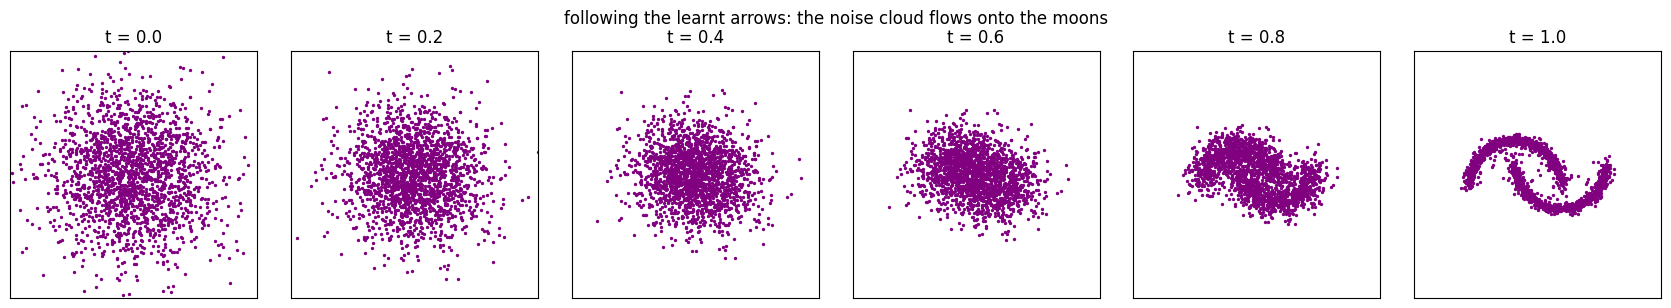

In [8]:
def euler(model, x0, steps, keep=False):
    """Follow the velocity field from t = 0 (noise) to t = 1 (data) in `steps` Euler steps.
    Returns the end points, and also the whole path of shape (steps + 1, n, 2) if keep is True."""
    x = x0.copy()
    path = [x.copy()]
    for i in range(steps):
        k = np.full(len(x), round(TICKS * i / steps), dtype="int32")   # the time now, in thousandths
        v = model.predict_on_batch([x, k])                             # one network call: the velocity here
        x = x + v / steps                                              # move for 1 / steps of the time
        if keep:
            path.append(x.copy())
    return (x, np.stack(path)) if keep else x

Z = np.random.default_rng(1).standard_normal((2000, 2)).astype("float32")   # 2,000 starting points, reused all lab
t0 = time.time()
gen100, path1 = euler(flow1, Z, 100, keep=True)
print(f"2,000 points, 100 network calls: {time.time() - t0:.2f} s")
score(X_REAL2, "2,000 fresh real points")
S1_100 = score(gen100, "flow matching, Euler, 100 steps")

fig, ax = plt.subplots(1, 6, figsize=(17, 3.1))
for a, i in zip(ax, (0, 20, 40, 60, 80, 100)):
    a.scatter(path1[i][:, 0], path1[i][:, 1], s=2, c="purple"); lims(a, 3.0); a.set_title(f"t = {i / 100:.1f}")
plt.suptitle("following the learnt arrows: the noise cloud flows onto the moons"); plt.tight_layout(); plt.show()

### Why we see this

The moons come out, and in a tenth of the calls Chapter 50 used: about 1% of the points are off the
moons, the same as its 1,000-step sampler, with the same coverage as real points. The average field
does carry the noise cloud onto the data cloud, although no traveller in training ever followed it.

Be fair about where the saving comes from. Much of it is the move from a random walk to a smooth,
deterministic path, and Chapter 51's deterministic sampler makes the same move for a diffusion model.
What flow matching adds is a shorter recipe (no schedule, no weights to derive) and a path that was
designed to be as straight as it can be made.

---
## Step 9 - How few steps?

> **Predict:** before you run it, fill in the share of points off the moons for 1, 2, 5 and 20 Euler
> steps. In particular: the paths in training were perfectly straight lines, and one Euler step along a
> straight line is exact. So is one step enough?

flow matching, 1 step              off 0.231 | miss 0.782 | further than 0.1 from any moon:  99.7% | std [0.04 0.03]


flow matching, 2 steps             off 0.101 | miss 0.188 | further than 0.1 from any moon:  47.1% | std [0.54 0.27]


flow matching, 5 steps             off 0.027 | miss 0.031 | further than 0.1 from any moon:   9.0% | std [0.8  0.48]


flow matching, 20 steps            off 0.012 | miss 0.019 | further than 0.1 from any moon:   1.4% | std [0.92 0.54]


flow matching, 100 steps           off 0.011 | miss 0.018 | further than 0.1 from any moon:   1.2% | std [0.95 0.55]

one step: mean of the samples [-0.007  0.014] | mean of the data [0.005 0.004]


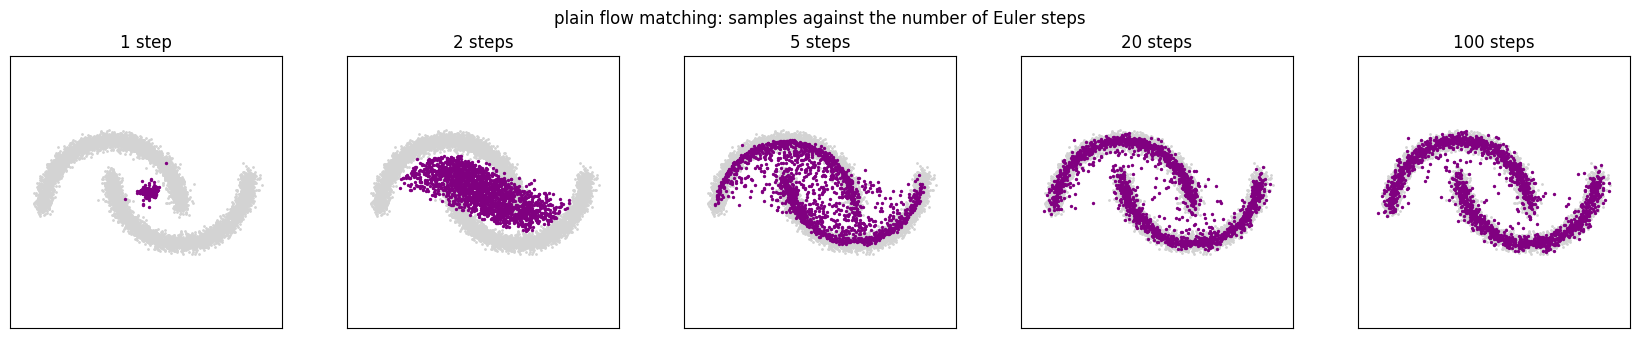

In [9]:
STEP_COUNTS = (1, 2, 5, 20, 100)
gens1 = {n: euler(flow1, Z, n) for n in STEP_COUNTS}
S1 = {n: score(gens1[n], f"flow matching, {n} step{'s' if n > 1 else ''}") for n in STEP_COUNTS}
print("\none step: mean of the samples", gens1[1].mean(0).round(3), "| mean of the data", X.mean(0).round(3))

def show_by_steps(gens, title):
    fig, ax = plt.subplots(1, len(gens), figsize=(3.4 * len(gens), 3.4))
    for a, (n, g) in zip(ax, gens.items()):
        a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); a.scatter(g[:, 0], g[:, 1], s=2, c="purple")
        lims(a, 2.2); a.set_title(f"{n} step{'s' if n > 1 else ''}")
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_by_steps(gens1, "plain flow matching: samples against the number of Euler steps")

### Why we see this

One step is a disaster of a very particular kind: **every sample lands on almost the same spot**, with a
spread of about 0.04, and that spot is the mean of the data, in the gap between the moons. Step 7 said
why. At t = 0 the network's answer is "towards the middle of the data", so one full-length step sends
every noise point to the middle. This is Chapter 50's one-jump blur again, for the same reason: one big
jump gives the average of the possibilities.

Two steps leave about half the points off the moons; five steps, about one in eleven; twenty steps are
within a whisker of a hundred. The training paths were straight, but the paths the sampler follows are
the **average field's** paths, and those are curved. Euler cuts every corner of a curve.

---
## Step 10 - How bent are the paths?

Put a number on "curved". For each of the 2,000 trajectories of the 100-step run, measure the distance
travelled and divide by the straight-line distance from start to finish. A perfectly straight path scores
1.00. Call it the **detour ratio**.

> **Predict:** is the typical detour ratio nearer 1.05, 1.3 or 2?

detour ratio, plain flow matching: median 1.96 | mean 2.63 | 9 in 10 are below 4.28
one Euler step lands 1.02 away, on average, from where 100 steps end


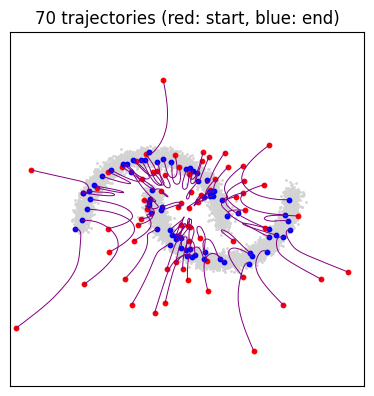

In [10]:
def detour(path):
    """Path length divided by the crow-flies distance from start to end, for each trajectory. 1.0 = straight."""
    travelled = np.linalg.norm(path[1:] - path[:-1], axis=-1).sum(0)
    crow = np.linalg.norm(path[-1] - path[0], axis=-1)
    return travelled / crow

def show_paths(path, title, n=70):
    fig, ax = plt.subplots(figsize=(4.6, 4.6))
    ax.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey")
    for j in range(n):
        ax.plot(path[:, j, 0], path[:, j, 1], c="purple", lw=0.7)
    ax.scatter(path[0, :n, 0], path[0, :n, 1], s=10, c="red"); ax.scatter(path[-1, :n, 0], path[-1, :n, 1], s=10, c="blue")
    lims(ax, 2.8); ax.set_title(title); plt.show()

d1 = detour(path1)
gap1 = np.linalg.norm(gens1[1] - gen100, axis=1).mean()
print(f"detour ratio, plain flow matching: median {np.median(d1):.2f} | mean {d1.mean():.2f} | 9 in 10 are below {np.quantile(d1, 0.9):.2f}")
print(f"one Euler step lands {gap1:.2f} away, on average, from where 100 steps end")
show_paths(path1, "70 trajectories (red: start, blue: end)")

### Why we see this

The typical path is about **twice as long** as the straight line between its ends. The plot shows the
shape of the detour: every traveller first heads for the middle (that is all the field can say at t = 0),
and only later, when its position starts to reveal which part of which moon it is bound for, swings out
towards it. Straight lines went into training. Hooks came out, because the field is an average over
crossing lines.

One step lands about 1.0 away from the true end point: the whole width of the data.

---
## Step 11 - The velocity field as arrows

The network is a function of place and time, so it can be drawn: a grid of places, an arrow at each, for
three moments.

> **Predict:** at t = 0, do the arrows point at the moons or at the centre? And where are the arrows
> longest?

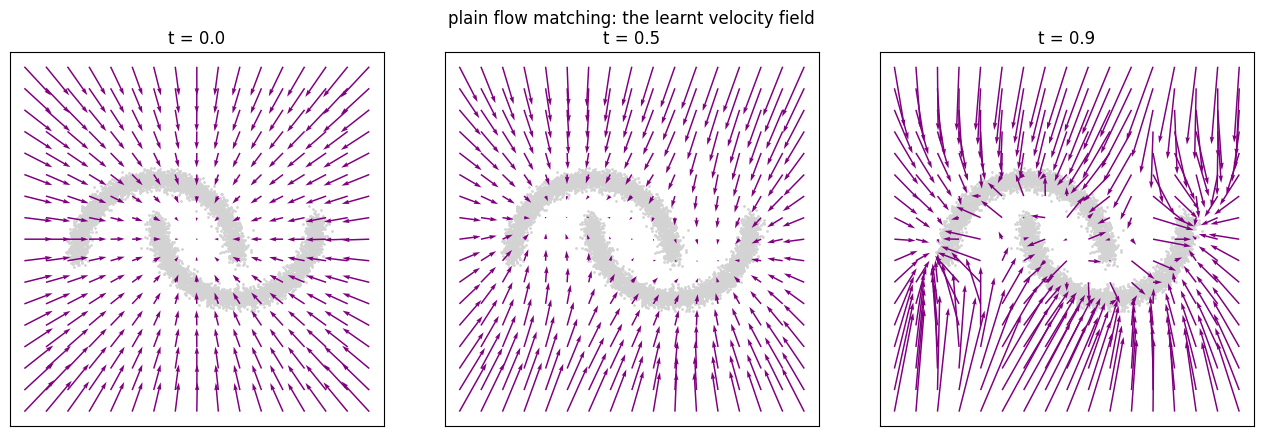

velocity at t = 0 at the places (2, 2), (-2, 0), (0, 0):
[[-1.96 -2.07]
 [ 1.94 -0.01]
 [-0.04  0.02]]   <- roughly 'minus where you are': straight at the centre


In [11]:
def show_field(model, title, times=(0.0, 0.5, 0.9)):
    g = np.linspace(-2.4, 2.4, 17, dtype="float32")
    grid = np.stack(np.meshgrid(g, g), -1).reshape(-1, 2)
    fig, ax = plt.subplots(1, len(times), figsize=(4.4 * len(times), 4.4))
    for a, t in zip(ax, times):
        v = model.predict([grid, np.full(len(grid), round(TICKS * t), dtype="int32")], verbose=0)
        a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey")
        a.quiver(grid[:, 0], grid[:, 1], v[:, 0], v[:, 1], color="purple", angles="xy", scale_units="xy", scale=6, width=0.004)
        lims(a, 2.6); a.set_title(f"t = {t}")
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_field(flow1, "plain flow matching: the learnt velocity field")
centre = flow1.predict([np.array([[2.0, 2.0], [-2.0, 0.0], [0.0, 0.0]], dtype="float32"), np.zeros(3, dtype="int32")], verbose=0)
print("velocity at t = 0 at the places (2, 2), (-2, 0), (0, 0):")
print(centre.round(2), "  <- roughly 'minus where you are': straight at the centre")

### Why we see this

At t = 0 every arrow points at the centre, and its length is the distance to the centre: the field is
"go to the middle of the data, in one unit of time". By t = 0.5 the arrows have started to split, left
and up for one moon, right and down for the other. At t = 0.9 they point at the nearest stretch of moon.
The field changes with time, and that change is the curvature of Step 10.

---
## Step 12 - A fixed map from noise to data

Euler's method adds no randomness, so the sampler is a **function**: the same noise point always ends at
the same place. Colour each starting point by the moon it ends on.

> **Predict:** will the two colours be mixed all over the noise cloud, or will the cloud be cut into two
> regions? And the few points that end between the moons: where in the noise cloud did they start?

largest difference between two runs from the same noise: 0.0


ends on the upper moon: 50.7% | on the lower moon: 49.2% | strays: 24 of 2000


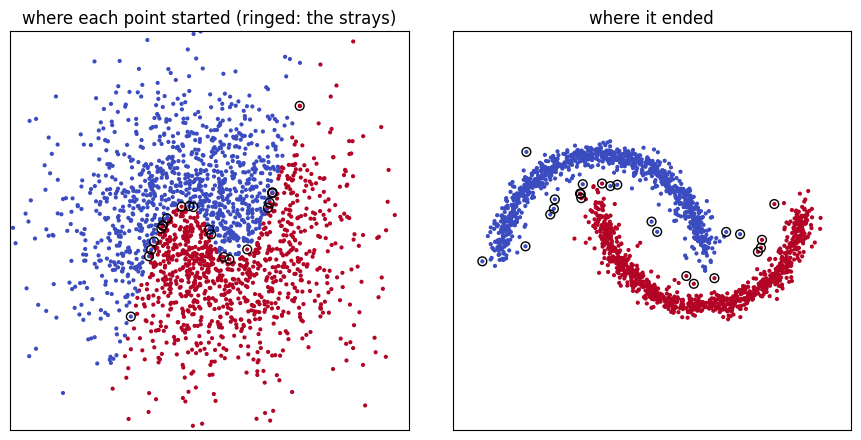

In [12]:
again = euler(flow1, Z, 100)
print("largest difference between two runs from the same noise:", float(np.abs(again - gen100).max()))

d2 = ((gen100[:, None, :] - X[None, :, :]) ** 2).sum(-1)
moon = Y[d2.argmin(1)]                                  # the moon of the nearest training point
stray = np.sqrt(d2.min(1)) > 0.1
print(f"ends on the upper moon: {100 * (moon == 0).mean():.1f}% | on the lower moon: {100 * (moon == 1).mean():.1f}% | strays: {stray.sum()} of {len(Z)}")

fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
ax[0].scatter(Z[:, 0], Z[:, 1], s=4, c=moon, cmap="coolwarm"); ax[0].scatter(Z[stray, 0], Z[stray, 1], s=40, facecolors="none", edgecolors="black")
lims(ax[0], 3.0); ax[0].set_title("where each point started (ringed: the strays)")
ax[1].scatter(gen100[:, 0], gen100[:, 1], s=4, c=moon, cmap="coolwarm"); ax[1].scatter(gen100[stray, 0], gen100[stray, 1], s=40, facecolors="none", edgecolors="black")
lims(ax[1], 2.2); ax[1].set_title("where it ended"); plt.tight_layout(); plt.show()

### Why we see this

Two runs agree to the last digit. The noise cloud is cut cleanly into two territories, one per moon, and
the strays started on the **border** between them. A smooth field cannot tear a cloud in two: neighbours
at the start stay neighbours all the way. So a thin strip of points along the border has to be stretched
across the gap between the moons, and that strip is most of the 1% that is off.

Chapter 50's sampler had no such map. It rolled dice at every step, and the same starting noise could end
anywhere. Here the starting noise **is** the sample, written in another form.

---
## Step 13 - Break it: the time, the wrong way round

This lab says t = 0 is noise. Chapters 50 and 51 said step 0 is data. Suppose the sampler was written by
someone holding the other convention: it starts from noise, as it should, but tells the network the time
is 1 and counts down.

> **Predict:** no shape is wrong, so nothing will crash. What will the samples look like?

clock reversed, 100 steps          off 0.125 | miss 0.116 | further than 0.1 from any moon:  53.5% | std [0.69 0.34]


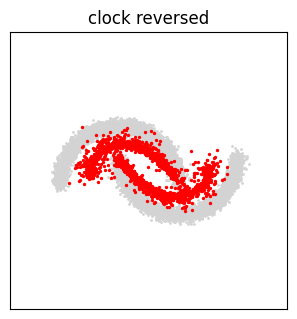

In [13]:
def euler_wrong_clock(model, x0, steps):
    """The same loop, but the clock runs from 1 down to 0 while the points still start as noise."""
    x = x0.copy()
    for i in range(steps):
        k = np.full(len(x), round(TICKS * (1 - i / steps)), dtype="int32")    # <- the bug: time reversed
        x = x + model.predict_on_batch([x, k]) / steps
    return x

wrong = euler_wrong_clock(flow1, Z, 100)
S_WRONG = score(wrong, "clock reversed, 100 steps")
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); ax.scatter(wrong[:, 0], wrong[:, 1], s=2, c="red"); lims(ax, 2.6)
ax.set_title("clock reversed"); plt.show()

### Why we see this

No error, and the result is the dangerous kind of wrong: a shrunken, smeared copy of the moons that
could pass for an under-trained model, with more than half of its points off them. The network is asked
first for the field of the last moments (fine adjustments near the moons) while the points are still a
round blob, and last for the field of the first moments ("everyone to the centre") when they should be
settling, so the finished cloud is pulled inwards. A reversed convention never crashes. It has to be
caught by measuring, and by knowing what the right picture looks like.

---
## Step 14 - Rectify: let the model choose the pairs

The paths bend because the pairs were made by chance, so the straight lines crossed. But the trained model
has itself produced a pairing that does **not** cross: each noise point and the place its own trajectory
ends (Step 12). **Rectified flow** uses that. Generate a large set of (noise, end point) pairs with the
model, then train a new network by the same recipe on straight lines between **those** pairs.

> **Predict:** making 80,000 pairs takes 100 network calls on a batch of 80,000. How good is this new
> training set, measured the way samples are? Can the new model be better than it?

80,000 pairs made in 6.2 s (100 network calls)


the pairs' data ends (first 2,000) off 0.010 | miss 0.018 | further than 0.1 from any moon:   0.9% | std [0.95 0.55]
mean length of a path: random pairs 1.593 | the model's pairs 0.525


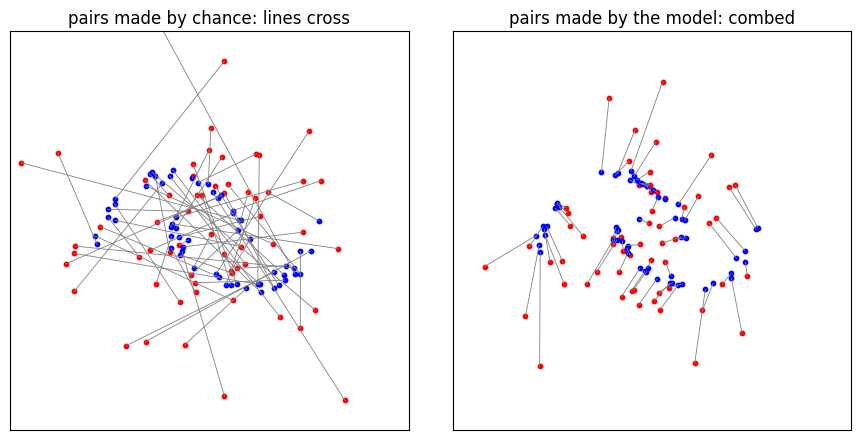

In [14]:
t0 = time.time()
Z_PAIR = np.random.default_rng(7).standard_normal((80000, 2)).astype("float32")   # the noise ends
X_PAIR = euler(flow1, Z_PAIR, 100)                                                # where flow1 sends each one
PAIRS_S = time.time() - t0
print(f"80,000 pairs made in {PAIRS_S:.1f} s (100 network calls)")
score(X_PAIR[:2000], "the pairs' data ends (first 2,000)")
print("mean length of a path: random pairs", np.linalg.norm(X - NOISE_EVAL, axis=1).mean().round(3),
      "| the model's pairs", np.linalg.norm(X_PAIR - Z_PAIR, axis=1).mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
for i in range(60):
    ax[0].plot([NOISE_EVAL[i, 0], X[i, 0]], [NOISE_EVAL[i, 1], X[i, 1]], c="grey", lw=0.6)
    ax[1].plot([Z_PAIR[i, 0], X_PAIR[i, 0]], [Z_PAIR[i, 1], X_PAIR[i, 1]], c="grey", lw=0.6)
ax[0].scatter(NOISE_EVAL[:60, 0], NOISE_EVAL[:60, 1], s=10, c="red"); ax[0].scatter(X[:60, 0], X[:60, 1], s=10, c="blue")
ax[1].scatter(Z_PAIR[:60, 0], Z_PAIR[:60, 1], s=10, c="red"); ax[1].scatter(X_PAIR[:60, 0], X_PAIR[:60, 1], s=10, c="blue")
lims(ax[0], 3.0); ax[0].set_title("pairs made by chance: lines cross"); lims(ax[1], 3.0); ax[1].set_title("pairs made by the model: combed")
plt.tight_layout(); plt.show()

### Why we see this

The model's pairs are a third as long on average and, in the picture, combed: each noise point is joined to a
data point on its own side. Lines that do not cross give the network one velocity per place and time,
with nothing to average over.

Notice what the new training set is. Its data ends are **samples from the first model**, not real data.
About 1% of them are off the moons. The second model is being taught to imitate the first, mistakes
included, and it cannot be expected to do better than its teacher.

---
## Step 15 - Train the second model on the model's own pairs

Same network, same recipe, same number of steps. The only change is the `noise` argument: every data row
keeps its own noise partner instead of getting a fresh random one each round.

> **Predict:** the first model's loss stopped at about 1.05 because crossing paths disagree. These paths
> hardly cross. Where will this loss stop?

In [15]:
keras.utils.set_random_seed(SEED + 1)
flow2 = build_denoiser(name="flow2")
t0 = time.time()
hist2 = train_flow(flow2, X_PAIR, noise=Z_PAIR, rounds=40, seed=SEED + 1)
TRAIN2_S = time.time() - t0
print(f"trained in {TRAIN2_S:.0f} s")
print(f"final loss: plain flow matching {hist1[-1]:.4f} | rectified {hist2[-1]:.5f}")

round   1 / 40   loss 0.0874


round   6 / 40   loss 0.0032


round  11 / 40   loss 0.0013


round  16 / 40   loss 0.0007


round  21 / 40   loss 0.0005


round  26 / 40   loss 0.0004


round  31 / 40   loss 0.0003


round  36 / 40   loss 0.0002


round  40 / 40   loss 0.0002
trained in 26 s
final loss: plain flow matching 1.0592 | rectified 0.00022


### Why we see this

The loss falls to about **0.0002**, thousands of times lower than the first model's. Nothing about the
network improved. The question became answerable: with combed pairs, a place and a time identify the
traveller, so the velocity can be predicted almost exactly.

Do not read that number as quality. The next step measures quality.

---
## Step 16 - One step, again

> **Predict:** fill in the table for the rectified model at 1, 2, 5, 20 and 100 steps. Then predict its
> detour ratio.

rectified, 1 step                  off 0.017 | miss 0.022 | further than 0.1 from any moon:   4.7% | std [0.95 0.54]


rectified, 2 steps                 off 0.016 | miss 0.019 | further than 0.1 from any moon:   3.5% | std [0.95 0.55]


rectified, 5 steps                 off 0.014 | miss 0.018 | further than 0.1 from any moon:   2.6% | std [0.95 0.55]


rectified, 20 steps                off 0.014 | miss 0.018 | further than 0.1 from any moon:   2.4% | std [0.95 0.55]


rectified, 100 steps               off 0.013 | miss 0.018 | further than 0.1 from any moon:   1.9% | std [0.95 0.55]



detour ratio: plain median 1.96 | rectified median 1.0001, 9 in 10 below 1.003
one Euler step lands, on average, this far from where 100 steps end: plain 1.02 | rectified 0.027
same noise, 100 steps, plain against rectified: the end points differ by 0.009 on average


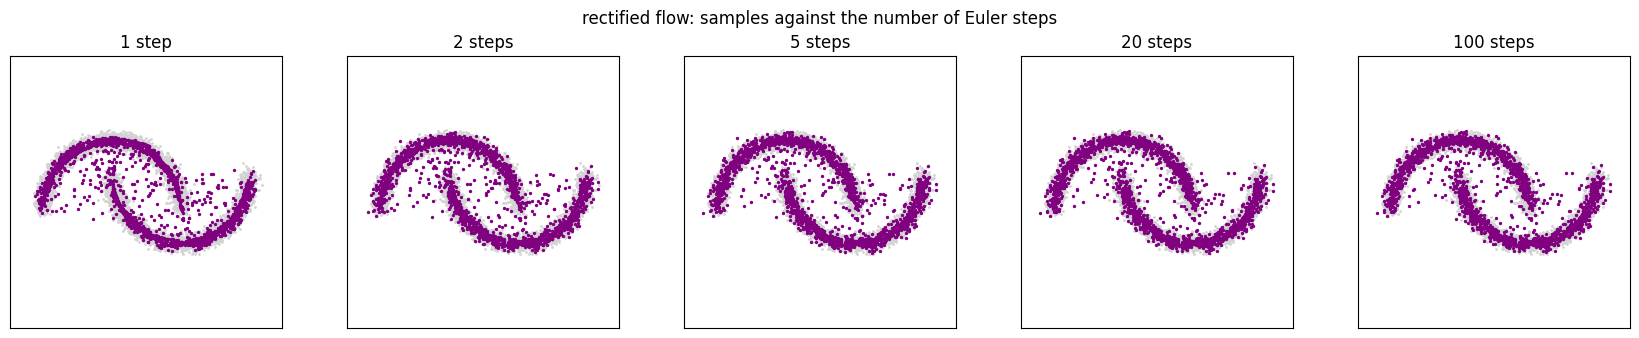

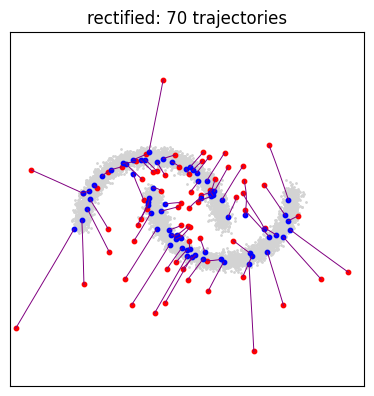

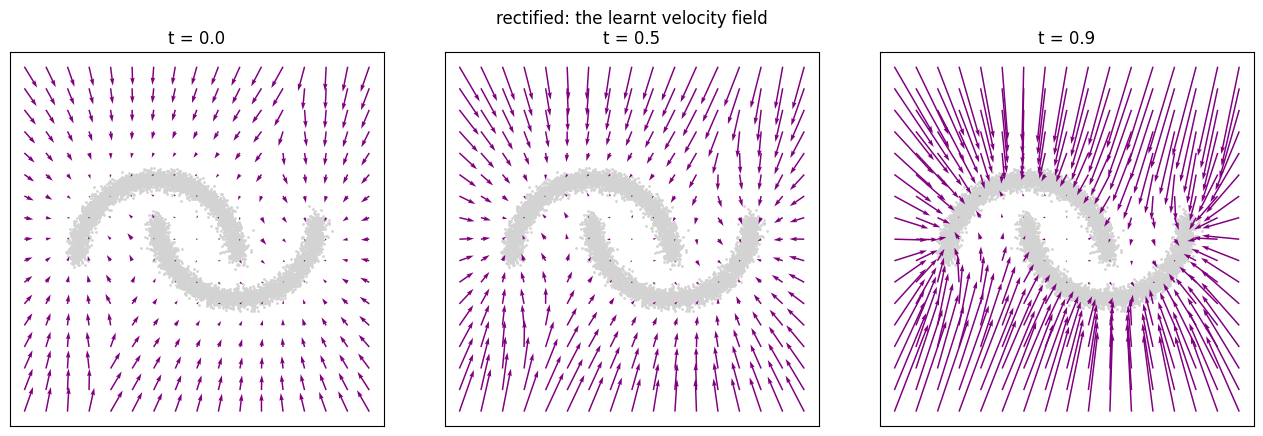

In [16]:
gens2 = {n: euler(flow2, Z, n) for n in STEP_COUNTS}
S2 = {n: score(gens2[n], f"rectified, {n} step{'s' if n > 1 else ''}") for n in STEP_COUNTS}
_, path2 = euler(flow2, Z, 100, keep=True)
d2r = detour(path2)
gap2 = np.linalg.norm(gens2[1] - gens2[100], axis=1).mean()
print(f"\ndetour ratio: plain median {np.median(d1):.2f} | rectified median {np.median(d2r):.4f}, 9 in 10 below {np.quantile(d2r, 0.9):.3f}")
print(f"one Euler step lands, on average, this far from where 100 steps end: plain {gap1:.2f} | rectified {gap2:.3f}")
print(f"same noise, 100 steps, plain against rectified: the end points differ by {np.linalg.norm(gens2[100] - gen100, axis=1).mean():.3f} on average")

show_by_steps(gens2, "rectified flow: samples against the number of Euler steps")
show_paths(path2, "rectified: 70 trajectories")
show_field(flow2, "rectified: the learnt velocity field")

### Why we see this

**One step now works.** A single network call puts two moons on the page, where the first model put a
dot. The paths are straight to within a fraction of a percent, the arrows at t = 0 already point at the
right part of the right moon, and the field hardly changes with time. One Euler step along a straight
path is exact, and these paths are nearly straight.

Now read the quality column honestly. The rectified model's **best** result, at 100 steps, is worse than
the first model's at 100 steps: more of its points are off the moons. And one step is worse than
its own hundred. So rectification did not make the model better. It moved the quality from "needs many
steps" to "available in one", and charged a fee: the second model learnt from the first model's samples,
and added its own errors to theirs.

The last line printed says the two models send the same noise point to almost the same place. The second
model is the first model's map, relearnt along straight lines.

---
## Step 17 - The bill for a second round

Rectification can be repeated: make pairs with the second model, train a third.

> **Predict:** the paths are already straight. Does another round buy anything? Does it cost anything?

second round of rectification: 35 s


rectified twice, 1 step            off 0.018 | miss 0.023 | further than 0.1 from any moon:   4.6% | std [0.95 0.55]


rectified twice, 2 steps           off 0.017 | miss 0.019 | further than 0.1 from any moon:   3.9% | std [0.95 0.55]


rectified twice, 5 steps           off 0.015 | miss 0.018 | further than 0.1 from any moon:   3.0% | std [0.95 0.55]


rectified twice, 20 steps          off 0.015 | miss 0.018 | further than 0.1 from any moon:   2.9% | std [0.95 0.55]


rectified twice, 100 steps         off 0.015 | miss 0.018 | further than 0.1 from any moon:   2.7% | std [0.95 0.55]



share of points further than 0.1 from any moon (%), by number of Euler steps = network calls
model                              1       2       5      20     100   detour   final loss
plain flow matching             99.7    47.1     9.0     1.4     1.2    1.958   1.05918
rectified once                   4.7     3.5     2.6     2.4     1.9    1.000   0.00022
rectified twice                  4.6     3.9     3.0     2.9     2.7    1.000   0.00016
fresh real points                0.0
Chapter 50's lab, same data and network: ancestral sampler, 1,000 steps: 1.1%; one jump from step 500: 66.8%


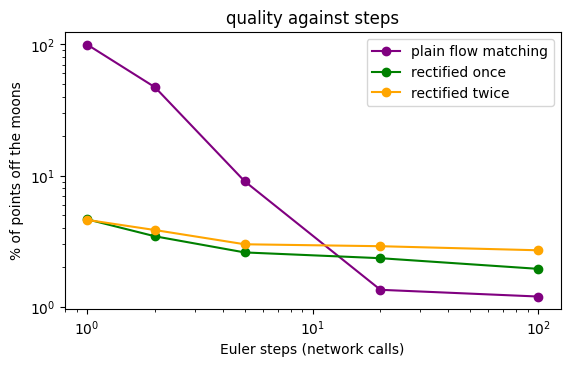


whole notebook: 113 s


In [17]:
t0 = time.time()
Z_PAIR3 = np.random.default_rng(8).standard_normal((80000, 2)).astype("float32")
X_PAIR3 = euler(flow2, Z_PAIR3, 100)
keras.utils.set_random_seed(SEED + 2)
flow3 = build_denoiser(name="flow3")
hist3 = train_flow(flow3, X_PAIR3, noise=Z_PAIR3, rounds=40, seed=SEED + 2, verbose=False)
print(f"second round of rectification: {time.time() - t0:.0f} s")
gens3 = {n: euler(flow3, Z, n) for n in STEP_COUNTS}
S3 = {n: score(gens3[n], f"rectified twice, {n} step{'s' if n > 1 else ''}") for n in STEP_COUNTS}
_, path3 = euler(flow3, Z, 100, keep=True)

print("\nshare of points further than 0.1 from any moon (%), by number of Euler steps = network calls")
print(f"{'model':28s}" + "".join(f"{n:>8d}" for n in STEP_COUNTS) + "   detour   final loss")
for name, S, d, h in (("plain flow matching", S1, d1, hist1), ("rectified once", S2, d2r, hist2), ("rectified twice", S3, detour(path3), hist3)):
    print(f"{name:28s}" + "".join(f"{100 * S[n][2]:8.1f}" for n in STEP_COUNTS) + f"   {np.median(d):6.3f}   {h[-1]:.5f}")
print(f"{'fresh real points':28s}" + f"{100 * REAL_SCORE[2]:8.1f}")
print("Chapter 50's lab, same data and network: ancestral sampler, 1,000 steps: 1.1%; one jump from step 500: 66.8%")

plt.figure(figsize=(6.4, 3.6))
for name, S, c in (("plain flow matching", S1, "purple"), ("rectified once", S2, "green"), ("rectified twice", S3, "orange")):
    plt.plot(STEP_COUNTS, [100 * S[n][2] for n in STEP_COUNTS], "o-", c=c, label=name)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("Euler steps (network calls)"); plt.ylabel("% of points off the moons")
plt.legend(); plt.title("quality against steps"); plt.show()
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

### Why we see this

The table is the chapter in one view.

- **Plain flow matching** is the best model when it is given enough steps and useless when it is given one.
- **Rectified once**, the curve is nearly flat: one step is almost as good as a hundred, and every entry
  on the right is worse than the plain model's.
- **Rectified twice**, nothing is gained (the paths were already straight) and a little more is lost. Each
  round is a copy of a copy.
- The final loss says the opposite of all this. The model with the loss near 1.05 makes the best samples.
  A loss measures how predictable the targets are, and rectification changed the targets.

Which model you want depends on what a network call costs you. For 2,000 points on a laptop, nothing. For
a large image model answering in real time, almost everything.

What changes at full size: the pairs for rectification cost a full many-step generation each, so making
a few million of them is a large bill in itself; and the quality lost shows up as detail and variety, not
as points off a moon. The small-model numbers above are for comparing rows of this table with each other.

---
## Trials: change one thing at a time

Change the one line, **predict**, then rerun from that step. Write the observation in the last column.

| # | Change | Where | Predict | Observe |
|---|---|---|---|---|
| 1 | `STEP_COUNTS = (1, 2, 3, 4, 5, 10, 20, 100)` | Step 9 | Between 2 and 5 steps the share off the moons falls from about a half to under a tenth. Is the fall even, or is there one step count where the moons appear? | |
| 2 | In `euler`, replace the step by a **midpoint** step: `xm = x + v / (2 * steps)`, ask the network again at `xm` and time `k + TICKS // (2 * steps)`, then `x = x + v_mid / steps` | Step 8 | Two calls per step. Is 10 midpoint steps (20 calls) better than 20 Euler steps (20 calls) on the plain model? On the rectified one? | |
| 3 | `X_PAIR = euler(flow1, Z_PAIR, 5)` | Step 14 | Pairs made with 5 steps are cheap and about 9% off the moons. What does the rectified model's whole row look like now? | |
| 4 | `Z_PAIR = ...standard_normal((8000, 2))` (a tenth of the pairs) | Step 14 | The loss will still be tiny. Will one-step quality hold up? What is the model short of? | |
| 5 | `x0 = 2 * rng.standard_normal(...)` in `train_flow` and `Z = 2 * Z` | Steps 6 and 8 | Noise twice as wide as the data. Do the paths cross more or less? Does the detour ratio go up or down? | |
| 6 | `k = rng.integers(0, TICKS, ...)` → `k = rng.integers(300, 700, ...)` in `train_flow` | Step 6 | The network never sees the start or the end of the journey. Which goes wrong: where the points head first, or how sharply they land? | |
| 7 | `flow2 = build_denoiser(use_time=False, name="flow2")` | Step 15 | Switch the clock off for the rectified model only. Its field hardly changes with time. Does it still work? Would the plain model? | |

---
## Exercises

1. **Count the calls.** Time one call of the network on 2,000 points. From the table in Step 17, find the
   cheapest way (model and step count) to get under 5% off the moons, and under 2%.
2. **Run it backwards.** Write `euler_back(model, x1, steps)` that starts from data at t = 1 and steps to
   t = 0 by subtracting the velocity. Send the 8,000 training points back. Is the result a round blob with
   a standard deviation of 1? Colour it by moon label and compare with Step 12.
3. **Distil without rectifying.** Train a network with **no time input** to map `Z_PAIR` straight to
   `X_PAIR` with one call (plain regression, MSE). Compare it with the rectified model's one-step row.
   What did the straight-line training add, if anything?
4. **A better pairing without a model.** Before training the first model, pair each batch's noise points
   with data points so that the total length of the lines is small (for instance, sort both by angle
   round the centre). Does the detour ratio of the plain model fall?
5. **Where the steps should go.** Replace the equal steps in `euler` by steps that are short at the start
   and long at the end, then the reverse. With 5 steps in total on the plain model, which helps? Use
   Step 11's pictures to say why.
6. **Add a label.** Give the network the moon label as a third input (Chapter 51 does this for diffusion)
   and train a conditional flow. Check that asking for moon 0 gives moon 0, and say what in this notebook
   did not have to change.

---
## Cheat sheet

| Thing | In one line |
|---|---|
| time convention (this lab) | t = 0 noise, t = 1 data; sampling runs forwards. Chapters 50 and 51 count the other way |
| path | x<sub>t</sub> = (1 − t) × noise + t × data: a straight line |
| target | velocity = data − noise, the same all along the line |
| training step | random pair, random t, MSE between the network's output at (x<sub>t</sub>, t) and data − noise |
| know-nothing loss | 1 + the data's variance: about 1.6 here |
| what the network learns | the **average** velocity of all paths through a place at a time |
| plain loss floor | about 1.05 here: crossing paths disagree; it says nothing about sample quality |
| sampler | Euler: x ← x + velocity / steps, from t = 0 to t = 1; one network call per step; no fresh noise |
| one step on a plain model | every sample at the mean of the data |
| detour ratio | path length ÷ straight-line distance; about 2 for the plain model, 1.00 after rectifying |
| rectified flow | make (noise, sample) pairs with the model, retrain on straight lines between them |
| what rectifying buys | one-step and few-step sampling |
| what it costs | a full sampling run per pair, a second training, and some quality in every round |
| the map | no randomness after the start: the same noise always gives the same sample |